# Oportuniza: perfis dos distritos de São Paulo e oferta de ETECs

Agrupamos os 96 distritos de São Paulo com PCA + KMeans, usando indicadores de vulnerabilidade social e a oferta de ETECs do Centro Paula Souza. A pergunta é: que tipo de distrito são Capão Redondo, Campo Limpo e Jardim Ângela, e como a oferta de ETEC aparece nesse perfil?

**Dados** (um arquivo, `base_distrital_oportuniza.csv`, uma linha por distrito):

- Indicadores sociais: [ObservaSampa](https://dados-abertos-observasampa.prefeitura.sp.gov.br/Download), referência 2022, acesso em 18/11/2026.
- ETECs e cursos: [Centro Paula Souza](https://dados.cps.sp.gov.br/onde-estudar-etecs/), consultado em 2026 (44 unidades no município).
- Distritos: [GeoSampa](https://metadados.geosampa.prefeitura.sp.gov.br/geonetwork/srv/api/records/af4dcf63-fe60-4066-8522-5ae2ac63fc5d), usado para localizar cada ETEC no seu distrito.

Os campos `_por_100mil_hab_proxy` dividem dados de 2026 (ETECs) ou contagens publicadas (social) pela população de 2022, então são aproximações. A oferta conta unidades e cursos listados no catálogo, não vagas nem matrículas, e só cobre ETEC (não inclui SENAI, CEUs ou ONGs). A documentação completa está em `FONTE_BASE_DISTRITAL.md`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_theme(style='whitegrid')
warnings.filterwarnings('ignore', category=RuntimeWarning)

caminho = Path('base_distrital_oportuniza.csv')
if not caminho.exists():
    from google.colab import files
    files.upload()

dados = pd.read_csv(caminho, keep_default_na=False)
print(dados.shape)

(96, 18)


In [2]:
variaveis = [
    'populacao_0_17_pct',
    'familias_extrema_pobreza_por_100mil_hab_proxy',
    'familias_baixa_renda_por_100mil_hab_proxy',
    'domicilios_favelas_por_100mil_hab_proxy',
    'taxa_universalizacao_educacao_basica_pct',
    'etecs_cps_por_100mil_hab_proxy',
    'registros_cursos_cps_por_100mil_hab_proxy',
]
focos = ['Capão Redondo', 'Campo Limpo', 'Jardim Ângela']

assert dados['distrito'].nunique() == 96
X = dados[variaveis].astype(float)
print('Valores ausentes nas variáveis do modelo:', int(X.isna().sum().sum()))

display(X.describe().T.round(2))
display(dados.loc[dados['distrito'].isin(focos),
                  ['distrito', 'etecs_cps_qtd_2026', 'registros_cursos_cps_qtd_2026']])

Valores ausentes nas variáveis do modelo: 0


,count,mean,std,min,25%,50%,75%,max
populacao_0_17_pct,96.0,22.06,4.69,10.01,18.36,22.09,25.90,32.66
familias_extrema_pobreza_por_100mil_hab_proxy,96.0,4998.84,2966.89,358.19,2772.24,4540.27,7283.22,13369.17
familias_baixa_renda_por_100mil_hab_proxy,96.0,2637.82,1367.12,276.18,1571.25,2603.25,3796.40,5172.72
domicilios_favelas_por_100mil_hab_proxy,96.0,2480.67,2702.67,0.00,332.70,1636.23,3383.88,13274.11
taxa_universalizacao_educacao_basica_pct,96.0,105.44,35.64,17.50,83.51,98.13,121.20,208.27
etecs_cps_por_100mil_hab_proxy,96.0,0.48,0.73,0.00,0.00,0.00,0.93,2.99
registros_cursos_cps_por_100mil_hab_proxy,96.0,8.06,14.35,0.00,0.00,0.00,9.64,68.23


,distrito,etecs_cps_qtd_2026,registros_cursos_cps_qtd_2026
16,Campo Limpo,0,0
18,Capão Redondo,0,0
41,Jardim Ângela,1,7


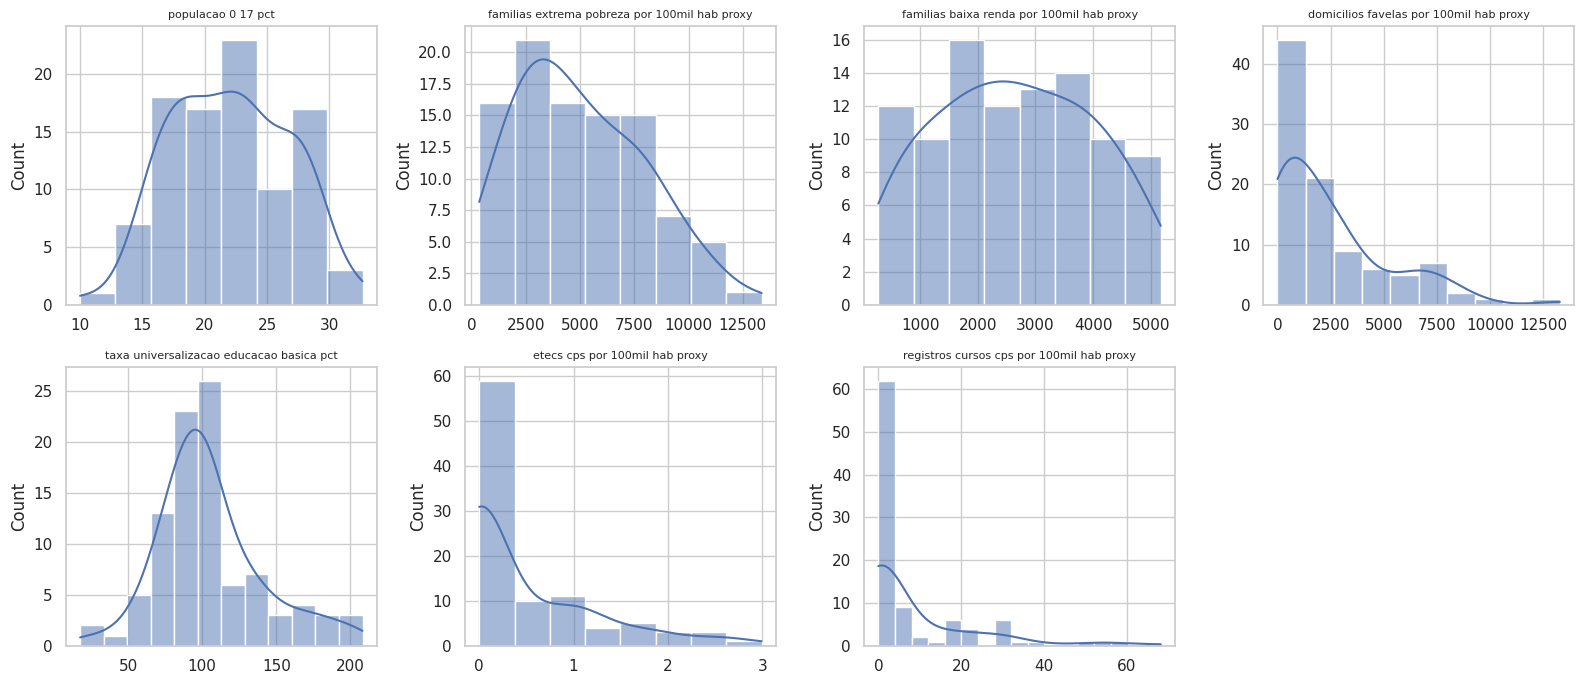

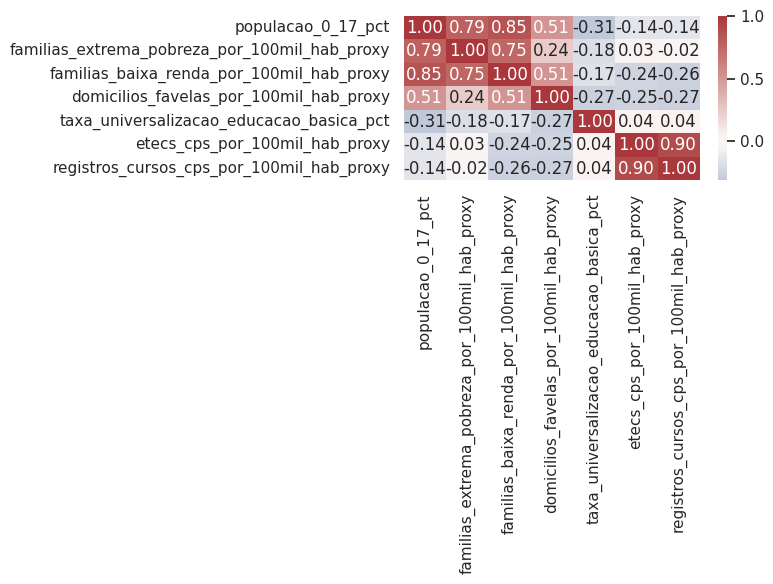

In [3]:
fig, eixos = plt.subplots(2, 4, figsize=(16, 7))
for eixo, col in zip(eixos.flat, variaveis):
    sns.histplot(X[col], kde=True, ax=eixo)
    eixo.set_title(col.replace('_', ' '), fontsize=8)
    eixo.set_xlabel('')
eixos.flat[-1].axis('off')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(X.corr(), annot=True, fmt='.2f', cmap='vlag', center=0)
plt.tight_layout()
plt.show()

## Escolha do modelo

Não existe uma variável-alvo (ninguém "rotulou" os distritos), então modelos supervisionados como XGBoost, Random Forest ou MLP não se aplicam. Queremos descobrir grupos de distritos parecidos, e para isso usamos KMeans.

Antes dele aplicamos PCA, porque os indicadores são muito correlacionados entre si (pobreza extrema, baixa renda e favelas andam juntas, como mostra o mapa de correlação). Sem o PCA, essa informação repetida pesaria demais na distância do KMeans.

## Treino e teste

Separamos 75% dos distritos para treino e 25% para teste. Escalonamento, PCA e KMeans são ajustados só com o treino. O teste apenas recebe essas transformações e é usado no fim, para ver se os grupos se mantêm em distritos que o modelo não viu.

In [4]:
X_treino, X_teste = train_test_split(X, test_size=0.25, random_state=42)

escalador = StandardScaler().fit(X_treino)
Z_treino = escalador.transform(X_treino)
Z_teste = escalador.transform(X_teste)

var = PCA().fit(Z_treino).explained_variance_ratio_
pd.DataFrame({'componente': range(1, len(var) + 1),
              'variancia': var.round(3),
              'acumulada': var.cumsum().round(3)})

,componente,variancia,acumulada
0,1,0.442,0.442
1,2,0.270,0.712
2,3,0.141,0.853
3,4,0.090,0.943
4,5,0.025,0.968
5,6,0.021,0.989
6,7,0.011,1.000


## Parâmetros e validação cruzada

Testamos três hiperparâmetros: número de componentes do PCA (2 a 5), número de grupos `k` (2 a 8) e inicialização do KMeans (`k-means++` ou `random`), o que dá 56 combinações. Cada uma é avaliada com validação cruzada de 5 folds **dentro do treino**: em cada fold, escalonamento, PCA e KMeans são ajustados nos outros 4 folds e a silhouette é medida no fold que ficou de fora.

A silhouette é calculada sempre no espaço padronizado original (e não nos componentes do PCA), para que combinações com número de componentes diferente possam ser comparadas.

,componentes,k,init,sil_treino_cv,sil_validacao_cv
0,2,2,k-means++,0.316,0.308
1,2,2,random,0.317,0.308
2,3,2,k-means++,0.317,0.308
3,3,2,random,0.317,0.308
4,4,2,k-means++,0.317,0.308
5,4,2,random,0.317,0.308
6,5,2,k-means++,0.317,0.308
7,5,2,random,0.317,0.308
8,3,3,k-means++,0.344,0.306
9,2,3,k-means++,0.340,0.303


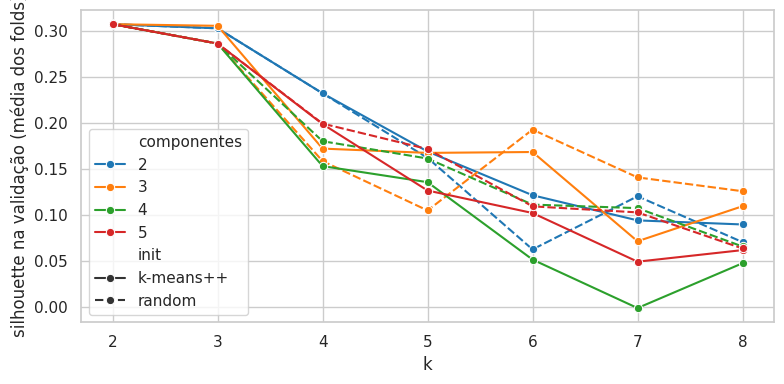

In [5]:
def silhouette(Z, rotulos):
    if 1 < len(np.unique(rotulos)) < len(rotulos):
        return silhouette_score(Z, rotulos)
    return np.nan

kf = KFold(n_splits=5, shuffle=True, random_state=42)
linhas = []

for n_comp in [2, 3, 4, 5]:
    for k in range(2, 9):
        for init in ['k-means++', 'random']:
            s_fold, s_val = [], []
            for i_tr, i_val in kf.split(X_treino):
                esc = StandardScaler().fit(X_treino.iloc[i_tr])
                Za = esc.transform(X_treino.iloc[i_tr])
                Zb = esc.transform(X_treino.iloc[i_val])
                pca = PCA(n_components=n_comp).fit(Za)
                km = KMeans(n_clusters=k, init=init, n_init=10, random_state=42)
                km.fit(pca.transform(Za))
                s_fold.append(silhouette(Za, km.labels_))
                s_val.append(silhouette(Zb, km.predict(pca.transform(Zb))))
            linhas.append({'componentes': n_comp, 'k': k, 'init': init,
                           'sil_treino_cv': np.nanmean(s_fold),
                           'sil_validacao_cv': np.nanmean(s_val)})

cv = (pd.DataFrame(linhas)
        .sort_values(['sil_validacao_cv', 'k'], ascending=[False, True])
        .reset_index(drop=True))
display(cv.head(10).round(3))

plt.figure(figsize=(8, 4))
sns.lineplot(data=cv, x='k', y='sil_validacao_cv', hue='componentes',
             style='init', marker='o', palette='tab10')
plt.ylabel('silhouette na validação (média dos folds)')
plt.tight_layout()
plt.show()

## Resultado em treino e teste

Pegamos a melhor combinação da validação cruzada, ajustamos no treino inteiro e comparamos a silhouette no treino e no teste.

{'k': 2, 'componentes': 2, 'init': 'k-means++'}
Silhouette no treino: 0.316
Silhouette na validação cruzada: 0.308
Silhouette no teste: 0.320
Diferença treino - teste: -0.005


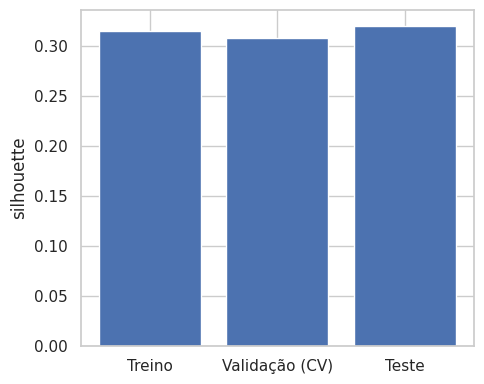

In [6]:
melhor = cv.iloc[0]
k = int(melhor['k'])
n_comp = int(melhor['componentes'])
init = melhor['init']
print({'k': k, 'componentes': n_comp, 'init': init})

pca_t = PCA(n_components=n_comp).fit(Z_treino)
km_t = KMeans(n_clusters=k, init=init, n_init=10, random_state=42)
km_t.fit(pca_t.transform(Z_treino))

sil_treino = silhouette(Z_treino, km_t.labels_)
sil_teste = silhouette(Z_teste, km_t.predict(pca_t.transform(Z_teste)))

print(f'Silhouette no treino: {sil_treino:.3f}')
print(f'Silhouette na validação cruzada: {melhor["sil_validacao_cv"]:.3f}')
print(f'Silhouette no teste: {sil_teste:.3f}')
print(f'Diferença treino - teste: {sil_treino - sil_teste:.3f}')

plt.figure(figsize=(5, 4))
plt.bar(['Treino', 'Validação (CV)', 'Teste'],
        [sil_treino, melhor['sil_validacao_cv'], sil_teste])
plt.ylabel('silhouette')
plt.tight_layout()
plt.show()

## Estabilidade e perfil dos grupos

Para ver se os grupos dependem dos distritos que entraram na amostra, refazemos o modelo em 30 amostras com reposição e comparamos com o agrupamento de referência pelo ARI (1 = mesmos grupos, perto de 0 = grupos diferentes). Depois descrevemos os grupos, ajustando o modelo com todos os distritos.

In [7]:
Z_all = StandardScaler().fit_transform(X)
P_all = PCA(n_components=n_comp).fit_transform(Z_all)
ref = KMeans(n_clusters=k, init=init, n_init=10, random_state=42).fit_predict(P_all)

rng = np.random.default_rng(42)
aris = []
for _ in range(30):
    idx = rng.choice(len(X), size=len(X), replace=True)
    esc = StandardScaler().fit(X.iloc[idx])
    pca = PCA(n_components=n_comp).fit(esc.transform(X.iloc[idx]))
    km = KMeans(n_clusters=k, init=init, n_init=10, random_state=42)
    km.fit(pca.transform(esc.transform(X.iloc[idx])))
    rot = km.predict(pca.transform(esc.transform(X)))
    aris.append(adjusted_rand_score(ref, rot))
print(f'ARI médio: {np.mean(aris):.3f} | mínimo: {np.min(aris):.3f}')

resultado = dados[['distrito'] + variaveis].copy()
resultado['cluster'] = ref
print()
print('Distritos por grupo:')
print(resultado['cluster'].value_counts().sort_index().to_string())
display(resultado.groupby('cluster')[variaveis].mean().round(2))

for d in focos:
    c = resultado.loc[resultado['distrito'] == d, 'cluster'].iloc[0]
    print(d, '-> cluster', c)

ARI médio: 0.947 | mínimo: 0.763

Distritos por grupo:
cluster
0    48
1    48


,populacao_0_17_pct,familias_extrema_pobreza_por_100mil_hab_proxy,familias_baixa_renda_por_100mil_hab_proxy,domicilios_favelas_por_100mil_hab_proxy,taxa_universalizacao_educacao_basica_pct,etecs_cps_por_100mil_hab_proxy,registros_cursos_cps_por_100mil_hab_proxy
cluster,,,,,,,
0,25.63,6825.09,3724.17,4183.26,96.96,0.17,1.78
1,18.49,3172.58,1551.46,778.09,113.92,0.79,14.33


Capão Redondo -> cluster 0
Campo Limpo -> cluster 0
Jardim Ângela -> cluster 0


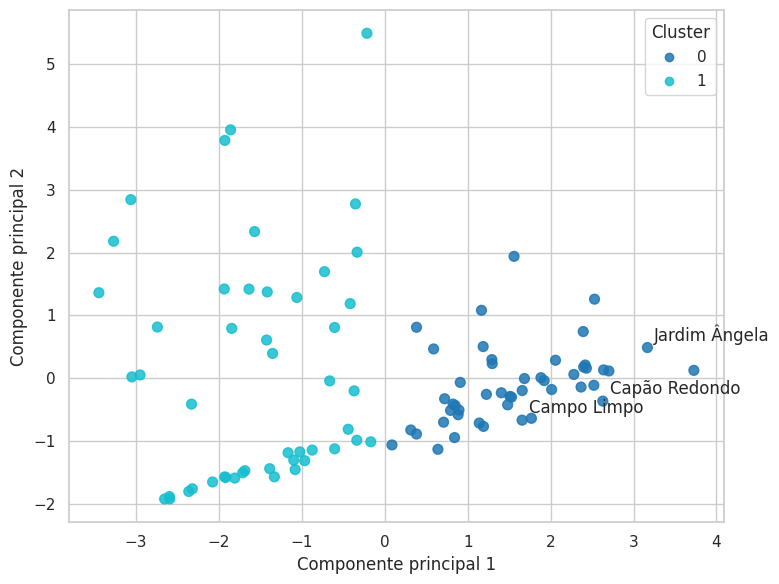

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(P_all[:, 0], P_all[:, 1], c=ref, cmap='tab10', s=50, alpha=0.85)
ax.legend(*sc.legend_elements(), title='Cluster')
for d in focos:
    i = dados.index[dados['distrito'] == d][0]
    ax.annotate(d, (P_all[i, 0], P_all[i, 1]), xytext=(5, 5), textcoords='offset points')
ax.set_xlabel('Componente principal 1')
ax.set_ylabel('Componente principal 2')
plt.tight_layout()
plt.show()

## Conclusão

**Modelo.** A melhor configuração na validação cruzada foi a impressa acima. A silhouette no treino e no teste ficou próxima, e a diferença entre as duas é pequena, o que indica que o modelo não está decorando o treino (sem sinais de overfitting). Isso precisa de cautela: o teste tem só 24 distritos, então a comparação é uma evidência modesta. O ARI nas amostras com reposição mostra se os mesmos distritos continuam juntos quando a amostra muda.

**Perfil dos grupos.** O grupo em que ficam Capão Redondo, Campo Limpo e Jardim Ângela é o de maior vulnerabilidade: tem a maior proporção de crianças e jovens (0 a 17 anos), mais famílias em pobreza extrema e baixa renda e mais domicílios em favelas. Nele a oferta de ETEC é baixa. Entre os três, Capão Redondo e Campo Limpo não têm nenhuma ETEC no catálogo e Jardim Ângela tem uma. O grupo com mais ETECs por habitante é de vulnerabilidade intermediária, e esse grupo é separado sobretudo pela presença de ETEC, já que a maioria dos distritos tem oferta zero.

**Para o cidadão.** Um jovem do Capão Redondo mora num tipo de distrito com muita demanda por oportunidades e pouca oferta de ETEC dentro do próprio território. Isso não quer dizer que ele não tenha acesso a cursos: pode estudar em ETECs de outros distritos, e o modelo não conhece transporte, vagas, critérios de seleção nem outras opções gratuitas (SENAI, CEUs, ONGs). Para orientar parcerias da Oportuniza, este diagnóstico deve ser combinado com uma lista validada de cursos e vagas.

**Limites.** Os dados misturam 2022 (social) e 2026 (ETEC), os indicadores são aproximações e as variáveis de ETEC têm muitos zeros. O KMeans mostra semelhanças entre distritos, mas não prova que renda ou oferta de ensino causem algum resultado.